In [1]:
#!pip install requests beautifulsoup4 plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Used in the advanced topic (web scraping and interactive maps)
import os
import time
import requests
import bs4
from bs4 import BeautifulSoup
import plotly
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Versions of the packages used
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('matplotlib:', plt.matplotlib.__version__)
print('seaborn:', sns.__version__)
print('requests:', requests.__version__)
print('beautifulsoup4:', bs4.__version__)
print('plotly:', plotly.__version__)

pandas: 3.0.3
,numpy: 2.4.6
,matplotlib: 3.11.0
,seaborn: 0.13.2
,requests: 2.34.2
,beautifulsoup4: 4.15.0
,plotly: 6.7.0


In [3]:
sns.set_style('whitegrid')
sns.set_palette('Set2')

## 1. Data loading

In [4]:
# Import dataset
df = pd.read_csv('artist_streams.csv',sep=',',parse_dates=['Update Date'])
df

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01,2026.0
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01,2026.0
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01,2026.0
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01,2026.0
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01,2026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
506,496,The Marías,NaN,United States,English,Pop,Group,2017.0,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01,2026.0
507,497,Limp Bizkit,Male,United States,English,Nu Metal,Group,1997.0,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01,2026.0
508,498,Korn,Male,United States,English,Metal,Group,1994.0,6976.4,4188.4,2798.5,6414.9,561.5,2026-07-01,2026.0
509,499,Omar Courtz,Male,United States,Spanish,Reggaeton,Solo,2017.0,6972.0,6956.0,20.3,1876.2,5095.8,2026-07-01,2026.0


In [5]:
df.sample(5)

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
95,94,OneRepublic,NaN,United States,English,Pop,Group,2007.0,21182.2,19519.4,1669.7,17506.6,3675.6,2026-07-01,2026.0
401,392,Mambo Kingz,Male,United States,Spanish,Reggaeton,Group,2004.0,8457.4,369.6,8087.7,1.3,8456.1,2026-07-01,2026.0
130,129,JHAYCO,Male,United States,Spanish,Reggaeton,Solo,2017.0,17516.1,16311.4,1210.7,2137.8,15378.3,2026-07-01,2026.0
256,252,John Legend,Male,United States,English,R&B,Solo,2004.0,11821.6,7454.6,4369.1,5783.2,6038.4,2026-07-01,2026.0
247,243,Gusttavo Lima,Male,Brazil,Portuguese,Sertanjeo,Solo,2009.0,12324.9,10393.6,1924.7,8841.9,3483.0,2026-07-01,2026.0


In [6]:
print('Initial Dimensions:', df.shape)

Initial Dimensions: (511, 15)


In [7]:
df.info()

<class 'pandas.DataFrame'>
,RangeIndex: 511 entries, 0 to 510
,Data columns (total 15 columns):
, #   Column                 Non-Null Count  Dtype         
,---  ------                 --------------  -----         
, 0   Artist ID              511 non-null    int64         
, 1   Artist Name            510 non-null    str           
, 2   Sex                    486 non-null    str           
, 3   Country of Origin      510 non-null    str           
, 4   Primary Language       510 non-null    str           
, 5   Primary Genre          510 non-null    str           
, 6   Artist Type            510 non-null    str           
, 7   Debut Year             510 non-null    float64       
, 8   Total Streams          505 non-null    float64       
, 9   Lead Streams           504 non-null    float64       
, 10  Feature Streams        499 non-null    float64       
, 11  Solo Streams           506 non-null    float64       
, 12  Collaborative Streams  509 non-null    float64       
, 13

In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Artist ID,511.0,249.956947,0.0,126.5,251.0,373.5,500.0,144.020444
Debut Year,510.0,2005.201961,1939.0,2001.0,2009.0,2014.0,2023.0,13.359191
Total Streams,505.0,16792.430891,6972.0,8809.4,11966.9,17738.8,137492.1,14771.249974
Lead Streams,504.0,12167.685516,0.0,6489.75,8756.7,13456.9,126177.3,11833.059565
Feature Streams,499.0,4675.36493,0.0,702.8,2993.2,6096.5,43710.5,5954.390999
Solo Streams,506.0,8348.897628,0.0,2505.925,6472.95,10127.05,113421.5,9600.760173
Collaborative Streams,509.0,8434.201768,0.0,1996.6,6578.1,10929.4,84168.2,9551.041044
Update Date,510,2026-06-23 20:14:07.058823,2025-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,NaN
Year,510.0,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0


First observations:
- There are 511 rows, but the `Artist ID` only goes from 0 to 500, so some rows must be repeated.
- Almost all columns have missing values.
- `Debut Year` and `Year` are floats and `Update Date` is text, so the types need to be fixed.
- The stream columns (in millions) have a mean much higher than the median, so a few artists have a lot more streams than the others.

## 2. Data Wrangling and Analysis

### Q1 – Duplicates, missing values and other data quality issues

#### Duplicates

In [9]:
# Number of duplicated rows
df.duplicated().sum()

np.int64(10)

In [10]:
# See the duplicated rows
df[df.duplicated(keep=False)]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
45,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01,2026.0
46,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01,2026.0
141,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01,2026.0
142,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01,2026.0
220,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01,2026.0
221,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01,2026.0
224,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01,2026.0
225,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01,2026.0
267,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01,2026.0
268,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01,2026.0


There are 10 rows that are exact copies of other rows (same ID and same values in every column). If we kept them, these artists would be counted twice, so we remove them.

In [11]:
df = df.drop_duplicates()

# Check that each ID and each name now appears only once
print(df['Artist ID'].duplicated().sum())
print(df['Artist Name'].duplicated().sum())

0
,0


#### Missing values

In [12]:
df.isna().sum()

Artist ID                 0
Artist Name               1
Sex                      23
Country of Origin         1
Primary Language          1
Primary Genre             1
Artist Type               1
Debut Year                1
Total Streams             6
Lead Streams              7
Feature Streams          10
Solo Streams              5
Collaborative Streams     2
Update Date               1
Year                      1
dtype: int64

In [13]:
# The row with the missing Artist Name
df[df['Artist Name'].isna()]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
510,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN


This row only has an ID and no other information, so we drop it.

In [14]:
df = df.drop(index=510)
df.isna().sum()

Artist ID                 0
Artist Name               0
Sex                      22
Country of Origin         0
Primary Language          0
Primary Genre             0
Artist Type               0
Debut Year                0
Total Streams             5
Lead Streams              6
Feature Streams           9
Solo Streams              4
Collaborative Streams     1
Update Date               0
Year                      0
dtype: int64

**Missing stream values.** The project description says that:
- Total Streams = Solo Streams + Collaborative Streams
- Total Streams = Lead Streams + Feature Streams


In [15]:
diff_solo = df['Total Streams'] - (df['Solo Streams'] + df['Collaborative Streams'])
diff_lead = df['Total Streams'] - (df['Lead Streams'] + df['Feature Streams'])

print('Total - (Solo + Collaborative):')
print(diff_solo.describe().round(2))
print('\nTotal - (Lead + Feature):')
print(diff_lead.describe().round(2))

Total - (Solo + Collaborative):
,count    490.0
,mean      -0.0
,std        0.0
,min       -0.0
,25%        0.0
,50%        0.0
,75%        0.0
,max        0.0
,dtype: float64
,
,Total - (Lead + Feature):
,count    480.00
,mean      -5.37
,std        9.37
,min      -39.20
,25%       -9.15
,50%       -5.00
,75%       -1.27
,max       89.20
,dtype: float64


- Solo + Collaborative is always exactly equal to Total.
- Lead + Feature is almost equal to Total (the difference is at most around 90 million, which is less than 1% of the streams of the artist).

Instead of dropping the rows or filling them with the mean, we can use these formulas to calculate the missing values from the other columns of the same row. First we check that no row has more than one missing stream value.

In [16]:
df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']].isna().sum(axis=1).value_counts()
# 475 artistas nao tÊm nenum valor nulo em nenhuma das 5 colunas
# 25 artistas têm 1 valor nulo em uma das 5 colunas

0    475
1     25
Name: count, dtype: int64

In [17]:
# Rows with a missing stream value (to check them after filling)
missing_rows = df[df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']].isna().sum(axis=1) > 0].index
missing_rows

Index([ 16,  47,  57, 107, 124, 131, 141, 169, 178, 185, 214, 227, 277, 293,
       297, 335, 343, 359, 377, 393, 395, 430, 482, 485, 494],
      dtype='int64')

In [18]:
df['Total Streams'] = df['Total Streams'].fillna(df['Solo Streams'] + df['Collaborative Streams'])
df['Solo Streams'] = df['Solo Streams'].fillna(df['Total Streams'] - df['Collaborative Streams'])
df['Collaborative Streams'] = df['Collaborative Streams'].fillna(df['Total Streams'] - df['Solo Streams'])
df['Lead Streams'] = df['Lead Streams'].fillna(df['Total Streams'] - df['Feature Streams'])
df['Feature Streams'] = df['Feature Streams'].fillna(df['Total Streams'] - df['Lead Streams'])

df.loc[missing_rows, ['Artist Name','Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
16,Future,53951.5,27879.0,26072.5,12647.5,41304.0
47,Peso Pluma,33179.8,18699.1,14501.2,3938.3,29241.5
57,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
107,Kygo,19707.8,17824.5,1883.3,250.7,19457.1
124,Sean Paul,18203.3,9663.9,8539.4,4460.6,13742.7
131,Bebe Rexha,17440.2,5928.1,11512.1,2784.0,14656.2
141,Fleetwood Mac,16577.5,16577.5,0.0,16567.4,10.1
169,A.R. Rahman,15240.4,10857.5,4397.5,594.9,14645.5
178,ROSALÍA,14558.4,10084.0,4474.4,5316.8,9241.6
185,Panic! At The Disco,14402.3,4417.2,9985.1,13038.0,1364.3


**Missing `Sex`.**

In [19]:
df[df['Sex'].isna()]['Artist Type'].value_counts()

Artist Type
Group    22
Name: count, dtype: int64

In [20]:
df[df['Sex'].isna()]['Artist Name'].values

<ArrowStringArray>
[               'Maroon 5',             'Linkin Park',
           'One Direction',                  'Disney',
   'Red Hot Chili Peppers',             'OneRepublic',
           'Fleetwood Mac',         'Black Eyed Peas',
    'Cigarettes After Sex',             'Major Lazer',
                    'ABBA',                'Paramore',
            'Clean Bandit',       'League of Legends',
                    'Maná',                'Måneskin',
               'SEVENTEEN',         'Backstreet Boys',
               'Aerosmith',      'Los Ángeles Azules',
 'Macklemore & Ryan Lewis',              'The Marías']
Length: 22, dtype: str

All 22 missing values are groups. Some of these groups have men and women (ABBA, Fleetwood Mac, Black Eyed Peas, Paramore) and some are not people at all (Disney, League of Legends). Filling them with "Male" (the most common value) would be wrong, so we create a new category `Mixed/Unknown`.

In [21]:
df['Sex'] = df['Sex'].fillna('Mixed/Unknown')
df['Sex'].value_counts()

Sex
Male             390
Female            88
Mixed/Unknown     22
Name: count, dtype: int64

#### Data types

In [22]:
df['Debut Year'] = df['Debut Year'].astype(int) # Debut year estava como float
df['Year'] = df['Year'].astype(int)  # Year estava como float
df.dtypes

Artist ID                         int64
Artist Name                         str
Sex                                 str
Country of Origin                   str
Primary Language                    str
Primary Genre                       str
Artist Type                         str
Debut Year                        int64
Total Streams                   float64
Lead Streams                    float64
Feature Streams                 float64
Solo Streams                    float64
Collaborative Streams           float64
Update Date              datetime64[us]
Year                              int64
dtype: object

#### Other data quality issues
We look at the unique values of the text columns to find errors.

In [23]:
print(df['Primary Genre'].unique())

<ArrowStringArray>
,[         'Hip-Hop',              'Pop',        'Reggaeton',
,              'R&B',            'K-Pop',             'Rock',
,      'Alternative',              'EDM',            'Filmi',
,            'Latin', 'Regional Mexican',          'Country',
,      'Spoken Word',       'Soundtrack',          'Bachata',
,        'Sertanjeo',           'Reggae',             'Folk',
,            'Metal',        'Afrobeats',             'Soul',
, 'Children's Music',         'Nu Metal']
,Length: 23, dtype: str


In [24]:
print(df['Country of Origin'].unique())

<ArrowStringArray>
,[             'Canada',       'United States',      'United Kingdom',
,            'Barbados',            'Colombia',         'South Korea',
, 'Trinidad and Tobago',              'France',               'India',
,            'Scotland',              'Mexico',           'Australia',
,             'Germany',                'Cuba',              'Sweden',
,              'Norway',              'Panama',              'Brazil',
,         'Netherlands',             'Jamaica',             'Senegal',
,             'Ireland',           'Argentina',               'Spain',
,               'Japan',         'New Zealand',             'Morocco',
,               'Chile',              'Russia',             'Nigeria',
,        'South Africa',           'Venezuela',               'Italy',
,  'Dominican Republic',             'Belgium',            'DR Congo',
,               'Nepal',            'Pakistan',           'Guatemala',
,             'Austria',         'Philippines',           

In [25]:
print(df['Primary Language'].unique())

<ArrowStringArray>
,[   'English',    'Spanish',     'Korean',      'Hindi',     'German',
, 'Portuguese',      'Tamil',     'French',    'Italian',       'Urdu',
,    'Punjabi']
,Length: 11, dtype: str


In [26]:
print(df['Artist Type'].unique())

<ArrowStringArray>
,['Solo', 'Group']
,Length: 2, dtype: str


Problems found:
- `Sertanjeo` is a spelling mistake. The genre is **Sertanejo**.
- `Scotland` appears as a country (Calvin Harris, Lewis Capaldi), but all other British artists are `United Kingdom`. We use `United Kingdom` so the UK isn't split in two.
- `Nu Metal` has only 1 artist and is a sub-genre of Metal, so we join it with `Metal`.

In [27]:
df['Primary Genre'] = df['Primary Genre'].replace({'Sertanjeo': 'Sertanejo', 'Nu Metal': 'Metal'})
df['Country of Origin'] = df['Country of Origin'].replace({'Scotland': 'United Kingdom'})

**Negative values and parts bigger than the total.**

In [31]:
print('Negative values:', (df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']] < 0).sum().sum())

Negative values: 2


In [32]:
print('Lead Streams bigger than Total Streams:', (df['Lead Streams'] > df['Total Streams']).sum())

Lead Streams bigger than Total: 38


In [35]:
df[df['Lead Streams'] > df['Total Streams']][['Artist Name', 'Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
57,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
60,One Direction,28889.5,28898.2,0.0,28801.9,87.6
63,Adele,28690.5,28699.5,0.0,28537.7,152.8
67,Arctic Monkeys,28155.4,28166.2,0.0,28130.4,25.0
73,The Beatles,26130.5,26138.7,2.2,26123.0,7.5
92,Red Hot Chili Peppers,21873.8,21884.2,0.0,21872.4,1.4
136,AC/DC,17010.5,17018.0,0.0,17010.5,0.0
145,Radiohead,16454.9,16461.5,3.0,16382.5,72.4
149,Nirvana,16228.7,16236.0,0.0,16228.7,0.0
194,Lewis Capaldi,14087.8,14091.2,0.0,13608.5,479.3


In [33]:
print('Feature Streams bigger than Total Streams:', (df['Feature Streams'] > df['Total Streams']).sum())

Feature Streams bigger than Total: 1


In [34]:
df[df['Feature Streams'] > df['Total Streams']][['Artist Name','Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
285,Little Mix,10985.7,0.0,11024.9,6916.9,4068.8


There are no negative values. Some artists have Lead (or Feature) slightly bigger than Total, but always by a very small amount (less than 1%), like we saw before. These are small errors in the source, so we keep `Total Streams` as the correct value and don't change these rows.

**Outliers.**

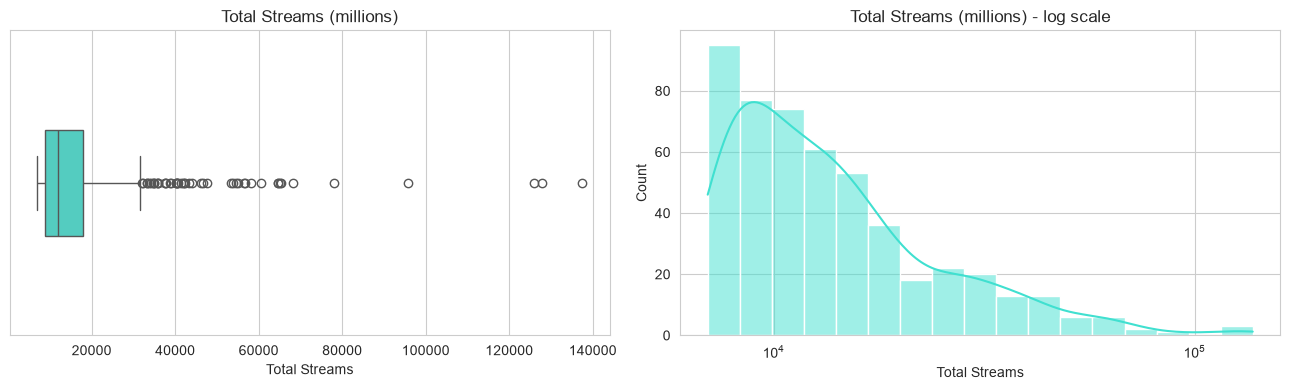

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x='Total Streams', width=0.35, color='turquoise', ax=ax1)
ax1.set_title('Total Streams (millions)')

sns.histplot(data=df, x='Total Streams', log_scale=True, kde=True, color='turquoise', ax=ax2)
ax2.set_title('Total Streams (millions) - log scale')

plt.tight_layout()
plt.show()

The boxplot shows many outliers, but there are some very big artists (Drake, Taylor Swift, Bad Bunny...), not errors. Removing them would remove the most successful artists, which is exactly what we want to study. So we keep them and use the **median** and **log scales** in the analysis.

**Other checks.**

In [41]:
print('Debut years from', df['Debut Year'].min(), 'to', df['Debut Year'].max())

Debut years from 1939 to 2023


In [62]:
values_of_year=df['Year'].unique()
print(f'Values of Year:{values_of_year}')

Values of Year:[2026]


- Debut years go from 1939 (Frank Sinatra) to 2023, which makes sense.
- `Year` is always 2026 (the year the data was extracted). We keep it to calculate the career length.
- 4 entries are not musicians but brands or series (Disney, League of Legends, and the German audio series Die drei ??? and Bibi Blocksberg). They are part of the streaming ranking, so we keep them, but we mark them so we can leave them out when we talk about artists.

In [69]:
df['Is Artist'] = ~df['Artist Name'].isin(['Disney', 'League of Legends', 'Die drei ???', 'Bibi Blocksberg'])
df.head()

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year,Is Artist
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01,2026,True
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01,2026,True
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01,2026,True
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01,2026,True
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01,2026,True


In [66]:
print('Missing values:', df.isna().sum().sum())

Missing values: 0


**Summary of Q1:**

| Problem | Decision |
|---|---|
| 10 duplicated rows | Removed |
| 1 empty row (only ID) | Removed |
| 25 missing stream values | Calculated with Total = Solo + Collab and Total = Lead + Feature |
| 22 missing `Sex` (all groups) | New category `Mixed/Unknown` |
| Wrong data types | Converted to int / datetime |
| `Sertanjeo`, `Nu Metal`, `Scotland` | Replaced by `Sertanejo`, `Metal`, `United Kingdom` |
| Lead/Feature slightly above Total | Kept (very small differences) |
| Outliers | Kept (real superstars) |
| 4 brands/series | Kept and marked with `Is Artist` |

The final dataset has **500 artists and no missing values**.

In [67]:
df.to_csv('artist_streams_clean.csv', index=False)

### Q2

**a) How many unique artists? How many pop artists?**

In [82]:
print('Unique artists:', len(df['Artist Name'].unique()))

Unique artists: 500


In [73]:
print('Pop artists:', (df['Primary Genre'] == 'Pop').sum())

Pop artists: 102


In [75]:
print('Pop artists:', (df['Primary Genre'] == 'K-Pop').sum())

Pop artists: 11


There are **500 unique artists**, and **102 are Pop** artists (113 if we also count K-Pop).

**b) Most common primary genre**

In [83]:
genres = df['Primary Genre'].value_counts()
genres

Primary Genre
Hip-Hop             115
Pop                 102
Rock                 60
Reggaeton            43
R&B                  31
Latin                30
EDM                  22
Regional Mexican     19
K-Pop                11
Filmi                11
Country              10
Alternative           9
Sertanejo             9
Metal                 9
Folk                  4
Soundtrack            3
Bachata               3
Soul                  3
Reggae                2
Afrobeats             2
Spoken Word           1
Children's Music      1
Name: count, dtype: int64

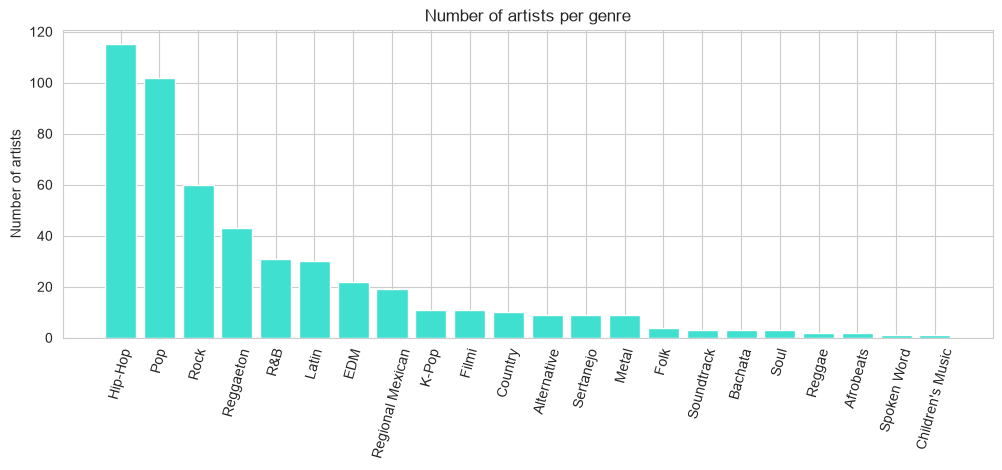

In [85]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(genres.index, genres.values, color='turquoise')
ax.set_xticks(range(len(genres.index)))
ax.set_xticklabels(genres.index, rotation=75)
ax.set_title('Number of artists per genre')
ax.set_ylabel('Number of artists')
plt.show()

The most common genre is **Hip-Hop, with 115 artists**, followed by Pop (102).

**c) Most common country of origin**

In [101]:
df['Country of Origin'].value_counts().head(10)

Country of Origin
United States     265
United Kingdom     57
Mexico             27
Canada             18
Colombia           16
Brazil             15
India              13
South Korea        11
Argentina           9
Australia           7
Name: count, dtype: int64

The most common country is the **United States, with 265 artists**. The United Kingdom comes second with 57.

**d) Top 3 primary languages**

In [100]:
languages = df['Primary Language'].value_counts()
languages.head(3)

Primary Language
English       340
Spanish       105
Portuguese     15
Name: count, dtype: int64

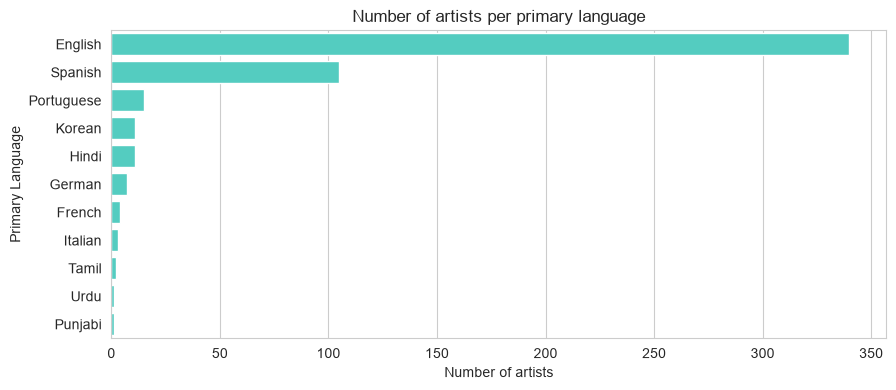

In [104]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=df, y='Primary Language', order=languages.index, color='turquoise', ax=ax)
ax.set_title('Number of artists per primary language')
ax.set_xlabel('Number of artists')
plt.show()

The top 3 languages are **English (340 artists), Spanish (105) and Portuguese (15)**.

### Q3

**a) How many days ago were the most recent and oldest updates?**

In [ ]:
today = pd.Timestamp.today().normalize()
most_recent = df['Update Date'].max()
oldest = df['Update Date'].min()

print('Most recent update:', most_recent.day, '/', most_recent.month, '/', most_recent.year,
      '->', (today - most_recent).days, 'days ago')
print('Oldest update:', oldest.day, '/', oldest.month, '/', oldest.year,
      '->', (today - oldest).days, 'days ago')

The most recent update was on **1 July 2026** and the oldest on **1 July 2025**. The number of days depends on the day the notebook is run (on 3 November 2026 it was 125 and 490 days).

**b) Artists with stream counts updated before the end of 2025**

In [ ]:
outdated = df[df['Update Date'] < '2026-01-01']
print(len(outdated), 'artists need an update')
outdated[['Artist Name', 'Update Date', 'Total Streams']]

**10 artists** were last updated in July 2025 and need an update: Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims, Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Kane Brown and Grupo Menos É Mais.

### Q4

**a) How does career length impact total streams?**

Career length = year of extraction (2026) − debut year.

In [107]:
df['Career Length'] = df['Year'] - df['Debut Year']
df

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year,Is Artist,Career Length
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01,2026,True,20
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01,2026,True,20
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01,2026,True,13
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01,2026,True,17
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01,2026,True,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,495,The Cure,Male,United Kingdom,English,Rock,Group,1979,7034.1,7035.0,3.3,6940.1,94.0,2026-07-01,2026,True,47
496,496,The Marías,Mixed/Unknown,United States,English,Pop,Group,2017,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01,2026,True,9
497,497,Limp Bizkit,Male,United States,English,Metal,Group,1997,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01,2026,True,29
498,498,Korn,Male,United States,English,Metal,Group,1994,6976.4,4188.4,2798.5,6414.9,561.5,2026-07-01,2026,True,32


In [108]:
# Correlation between career length and total streams
# (Spearman uses the ranks, so it is not affected by the outliers)
df[['Career Length', 'Total Streams']].corr(method='spearman')

,Career Length,Total Streams
Career Length,1.000000,-0.012477
Total Streams,-0.012477,1.000000


In [113]:
# Group the career length in intervals
df['Career Group'] = pd.cut(df['Career Length'], bins=[0, 5, 10, 15, 20, 30, 90],
                            labels=['0-5', '6-10', '11-15', '16-20', '21-30', '30+'])
df.groupby('Career Group')['Total Streams'].agg(['count', 'median', 'mean']).round(0)

,count,median,mean
Career Group,,,
0-5,8,9902.0,12554.0
6-10,76,10865.0,13033.0
11-15,134,13480.0,19467.0
16-20,111,12994.0,19260.0
21-30,90,11560.0,16581.0
30+,81,10760.0,13324.0


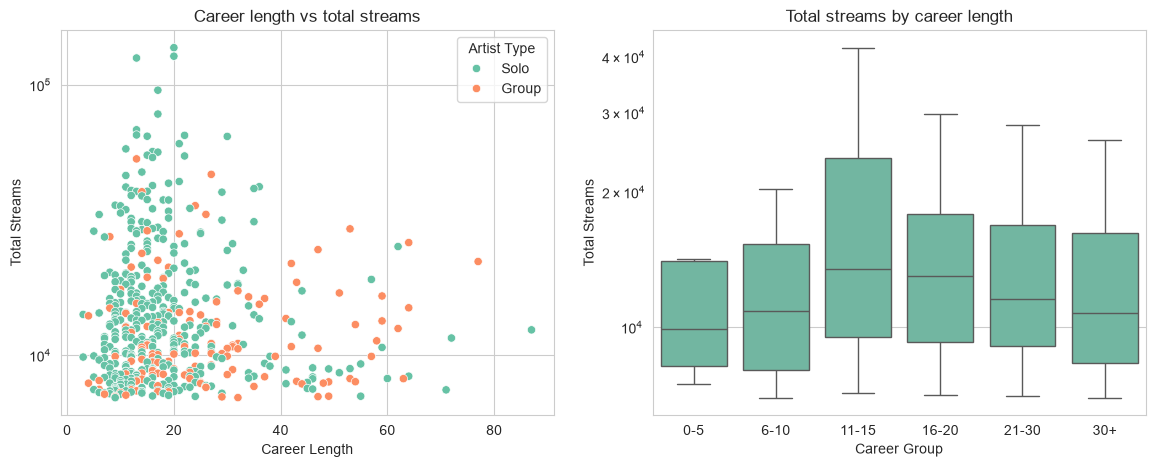

In [116]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='Career Length', y='Total Streams', hue='Artist Type', ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Career length vs total streams')

sns.boxplot(data=df, x='Career Group', y='Total Streams', showfliers=False, ax=ax2)
ax2.set_yscale('log')
ax2.set_title('Total streams by career length')
plt.show()

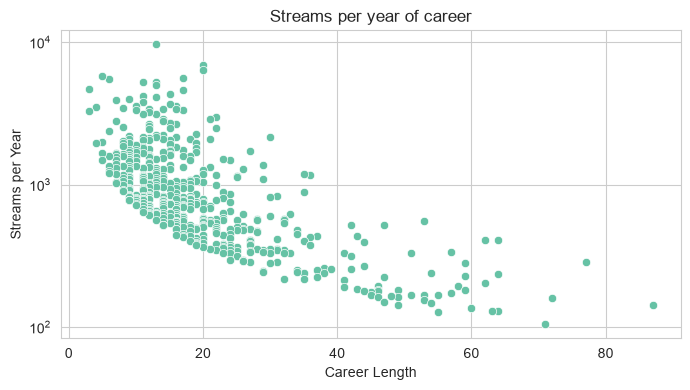

In [118]:
# Streams per year of career
df['Streams per Year'] = df['Total Streams'] / df['Career Length']

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=df, x='Career Length', y='Streams per Year', ax=ax)
ax.set_yscale('log')
ax.set_title('Streams per year of career')
plt.show()

In [119]:
df[['Career Length', 'Streams per Year']].corr(method='spearman')

,Career Length,Streams per Year
Career Length,1.000000,-0.717222
Streams per Year,-0.717222,1.000000


**Conclusion:** career length has **almost no relation with total streams** (correlation ≈ −0.01). Artists with 11 to 20 years of career have the highest median, but the differences are small.

The reason is that streaming platforms only exist since around 2008. Older artists did most of their career before streaming, so a longer career doesn't mean more streams. On the other hand, **streams per year of career go down a lot with career length** (correlation ≈ −0.72): recent artists like Peso Pluma reach the top in a few years, while artists like The Beatles or Frank Sinatra needed decades. Being in the streaming era matters more than having a long career.

**b) Top 5 artists that benefit the most from collaborations**

In [121]:
df['% Solo'] = df['Solo Streams'] / df['Total Streams'] * 100
df['% Collab'] = df['Collaborative Streams'] / df['Total Streams'] * 100
df

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,...,Solo Streams,Collaborative Streams,Update Date,Year,Is Artist,Career Length,Career Group,Streams per Year,% Solo,% Collab
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,...,53323.9,84168.2,2026-07-01,2026,True,20,16-20,6874.605000,38.783246,61.216754
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,...,113421.5,14439.5,2026-07-01,2026,True,20,16-20,6393.050000,88.706877,11.293123
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,...,48887.0,77012.8,2026-07-01,2026,True,13,11-15,9684.600000,38.830086,61.169914
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,...,51020.0,44683.2,2026-07-01,2026,True,17,16-20,5629.600000,53.310652,46.689348
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,...,29638.3,48466.1,2026-07-01,2026,True,17,16-20,4594.376471,37.947030,62.052970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,495,The Cure,Male,United Kingdom,English,Rock,Group,1979,7034.1,7035.0,...,6940.1,94.0,2026-07-01,2026,True,47,30+,149.661702,98.663653,1.336347
496,496,The Marías,Mixed/Unknown,United States,English,Pop,Group,2017,7029.1,5774.4,...,5705.9,1323.2,2026-07-01,2026,True,9,6-10,781.011111,81.175399,18.824601
497,497,Limp Bizkit,Male,United States,English,Metal,Group,1997,7018.9,7018.4,...,6806.0,212.9,2026-07-01,2026,True,29,21-30,242.031034,96.966761,3.033239
498,498,Korn,Male,United States,English,Metal,Group,1994,6976.4,4188.4,...,6414.9,561.5,2026-07-01,2026,True,32,30+,218.012500,91.951436,8.048564


In [122]:
collab = df[df['Is Artist']].sort_values(['% Collab', 'Collaborative Streams'], ascending=False)
collab[['Artist Name', 'Primary Genre', 'Country of Origin', '% Collab', 'Collaborative Streams']].head(10).round(2)

,Artist Name,Primary Genre,Country of Origin,% Collab,Collaborative Streams
246,Amitabh Bhattacharya,Filmi,India,100.00,12136.7
277,Irshad Kamil,Filmi,India,100.00,11014.9
372,DJ Luian,Reggaeton,United States,100.00,8801.6
447,Kumaar,Pop,India,100.00,7689.5
483,Magenta,Pop,Italy,100.00,7239.7
484,Ryan Lewis,Hip-Hop,United States,100.00,7237.6
392,Mambo Kingz,Reggaeton,United States,99.98,8456.1
63,Pritam,Pop,India,99.96,28532.2
489,benny blanco,Pop,United States,99.95,7110.2
256,MC Ryan SP,Hip-Hop,Brazil,99.93,11707.4


Several artists have 100% of their streams from collaborations, so to choose the top 5 we:
1. sort by % of collaborative streams;
2. in case of a tie, sort by the number of collaborative streams (more streams = more benefit);
3. leave out Disney, because it is a brand and not an artist.

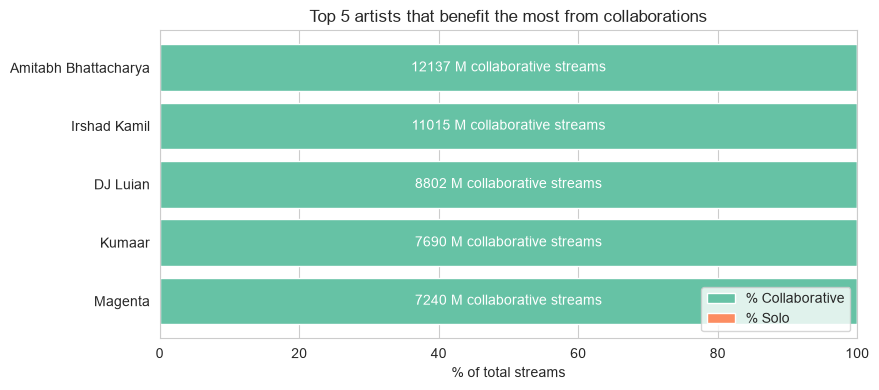

In [125]:
top5 = collab.head(5)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top5['Artist Name'], top5['% Collab'], label='% Collaborative')
ax.barh(top5['Artist Name'], top5['% Solo'], left=top5['% Collab'], label='% Solo')
ax.invert_yaxis()
for i, value in enumerate(top5['Collaborative Streams']):
    ax.text(50, i, str(round(value)) + ' M collaborative streams', va='center', ha='center', color='white')
ax.set_xlabel('% of total streams')
ax.set_title('Top 5 artists that benefit the most from collaborations')
ax.legend(loc='lower right')
plt.show()

The top 5 are **Amitabh Bhattacharya, Irshad Kamil, DJ Luian, Kumaar and Magenta**, all with 100% of their streams from collaborations. Amitabh Bhattacharya, Irshad Kamil and Kumaar write lyrics for Bollywood films, and DJ Luian is a reggaeton producer. Lyricists and producers are always credited together with a singer, which explains why all their streams are collaborative.

### Q5 – Three additional insights

**Insight 1 – A small group of artists has a big part of the streams**

In [130]:
sorted_streams = df['Total Streams'].sort_values(ascending=False)
print(sorted_streams)

0      137492.1
,1      127861.0
,2      125899.8
,3       95703.2
,4       78104.4
,         ...   
,495      7034.1
,496      7029.1
,497      7018.9
,498      6976.4
,499      6972.0
,Name: Total Streams, Length: 500, dtype: float64


In [131]:
total = sorted_streams.sum()
print('Top 10 artists:', round(sorted_streams.head(10).sum() / total * 100, 1), '% of the streams')
print('Top 50 artists:', round(sorted_streams.head(50).sum() / total * 100, 1), '% of the streams')
print('Top 100 artists:', round(sorted_streams.head(100).sum() / total * 100, 1), '% of the streams')

Top 10 artists: 10.6 % of the streams
,Top 50 artists: 30.6 % of the streams
,Top 100 artists: 45.9 % of the streams


In [ ]:
cumulative = sorted_streams.cumsum() / total * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative.values)
ax.plot([0, 500], [0, 100], linestyle='--', color='grey', label='If all artists had the same streams')
ax.set_xlabel('Number of artists (from the most streamed)')
ax.set_ylabel('% of total streams')
ax.set_title('Cumulative % of streams')
ax.legend()
plt.show()

Even among the 500 most streamed artists, the streams are concentrated: the **top 10 artists (2%) have 10.6% of all streams** and the **top 50 (10%) have 30.6%**.

**Insight 2 – Collaborations depend a lot on the genre and the language**

In [ ]:
# Genres with at least 9 artists, ordered by median % collab
big_genres = genres[genres >= 9].index
order = df[df['Primary Genre'].isin(big_genres)].groupby('Primary Genre')['% Collab'].median().sort_values(ascending=False)
order.round(1)

In [ ]:
df['English'] = np.where(df['Primary Language'] == 'English', 'English', 'Other languages')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 1]})
sns.boxplot(data=df[df['Primary Genre'].isin(big_genres)], x='Primary Genre', y='% Collab', order=order.index, ax=ax1)
ax1.set_xticks(range(len(order.index)))
ax1.set_xticklabels(order.index, rotation=45)
ax1.set_title('% of collaborative streams by genre')
sns.boxplot(data=df, x='English', y='% Collab', ax=ax2)
ax2.set_title('English vs other languages')
plt.show()

df.groupby('English')['% Collab'].median()

- **Filmi (Indian film music), EDM and Reggaeton** artists get more than 85% of their streams from collaborations, while **Rock** artists get almost none (median 2%). Bands usually play their own songs, while in EDM the producers need singers, and in Reggaeton featurings are very common.
- Artists who don't sing in English depend much more on collaborations (median 73% vs 40%). Collaborating is a way for them to reach new audiences.

**Insight 3 – There are few women, but they are as successful as men**

In [ ]:
solo = df[df['Artist Type'] == 'Solo']
solo.groupby('Sex')['Total Streams'].agg(['count', 'median', 'mean']).round(0)

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=solo, y='Primary Genre', hue='Sex', order=solo['Primary Genre'].value_counts().index[:8], ax=ax1)
ax1.set_title('Solo artists by genre and sex')
sns.boxplot(data=solo, x='Sex', y='Total Streams', showfliers=False, ax=ax2)
ax2.set_title('Total streams of solo artists by sex')
plt.show()